# TP3 : un CNN pour classer les images CIFAR-10

Objectif : reprendre la tâche du TP2 avec un réseau convolutif. Vous construisez le pipeline complet (transforms, ImageFolder, DataLoader), un CNN de trois blocs, vous visualisez ce que détecte sa première couche, puis vous mesurez le gain par rapport au MLP du TP2, sur les mêmes images.

L'énoncé complet, avec les critères de réussite, est dans `enonce.md`.

**Corrigé.** *Les sorties enregistrées dans ce notebook viennent d'une exécution dans Google Colab sur GPU A100, avec la graine fixée. Sur un autre GPU ou sur CPU, certaines valeurs peuvent légèrement différer : PyTorch ne garantit pas des résultats identiques d'une plateforme à l'autre.*

## Installation

Cette cellule écrit `requirements-colab.txt` (les versions de la formation, alignées sur le runtime Colab), puis l'installe avec uv. Les paquets déjà présents à la bonne version ne sont pas réinstallés. Hors de Colab, elle n'installe rien : l'environnement uv du projet contient déjà ces versions.

In [ ]:
import importlib.util
from pathlib import Path

Path("requirements-colab.txt").write_text("""torch==2.11.0
torchvision==0.26.0
numpy==2.1.3
matplotlib==3.10.0
pillow==11.3.0
scikit-learn==1.6.1
pandas==2.2.2; python_version < "3.13"
pandas==2.2.3; python_version >= "3.13"
pyarrow>=14
tensorboard==2.21.0
torchviz==0.0.3
onnx==1.23.0
onnxruntime==1.30.0
onnxscript==0.7.2
torchserve==0.12.0
torch-model-archiver==0.12.0
""")

if importlib.util.find_spec("google.colab") is not None:
    %pip install -q --progress-bar off uv
    !uv pip install --system -q -r requirements-colab.txt
else:
    print("Hors Colab : environnement uv du projet, rien à installer.")

## Préparation (fournie)

**Données** : CIFAR-10 (Krizhevsky, Nair et Hinton, 2009), fourni par torchvision : des photos couleur de 32 x 32 pixels, en 10 classes (avion, automobile, oiseau, chat, cerf, chien, grenouille, cheval, bateau, camion). Le site du jeu ne donne pas de licence ; il demande de citer le rapport *Learning Multiple Layers of Features from Tiny Images* (Krizhevsky, 2009). Tous les TP utilisent les mêmes images : 5000 d'entraînement et 1000 de validation, tirées de l'entraînement de CIFAR-10, et 1000 de test.

Les images sont rangées au format ImageFolder : `cifar10/<partie>/<classe>/`.

In [ ]:
def preparer_archive_cifar10(racine="data"):
    """Place les fichiers de CIFAR-10 dans racine/cifar-10-batches-py sans passer par le serveur d'origine, lent.

    Dans l'ordre : fichiers déjà décompressés ; archive déposée dans la session (cifar-10-python.tar.gz ou
    cifar-10-batches-py.tar.gz, dans le dossier du notebook ou dans racine) ; archive d'origine copiée sur le
    Google Drive de la formation. Si rien n'aboutit, torchvision télécharge ensuite depuis le serveur d'origine ;
    dans tous les cas, il vérifie l'intégrité des fichiers.
    """
    import tarfile
    import urllib.request
    from pathlib import Path

    if Path(racine, "cifar-10-batches-py").exists():
        return
    noms = ("cifar-10-python.tar.gz", "cifar-10-batches-py.tar.gz")
    deposees = [Path(dossier, nom) for dossier in (".", racine) for nom in noms if Path(dossier, nom).exists()]
    if deposees:
        archive = deposees[0]
        print(f"Archive trouvée : {archive}")
    else:
        archive = Path(racine, "cifar-10-python.tar.gz")
        archive.parent.mkdir(parents=True, exist_ok=True)
        url = ("https://drive.usercontent.google.com/download?id=1kyq-1VhOPNr2Bo0w5DiLYuNghOdOWl0a"
               "&export=download&confirm=t")
        print("Téléchargement de CIFAR-10 depuis le Google Drive de la formation (170 Mo)...")
        try:
            urllib.request.urlretrieve(url, archive)
        except OSError as erreur:
            print(f"Google Drive indisponible ({erreur}) : téléchargement depuis le serveur d'origine.")
            return
    try:
        with tarfile.open(archive) as contenu:
            contenu.extractall(racine, filter="data")
    except tarfile.TarError:
        print(f"{archive} n'est pas une archive valide : téléchargement depuis le serveur d'origine.")


def charger_cifar10(dossier="cifar10", n_train=5000, n_val=1000, n_test=1000, seed=0):
    """Images CIFAR-10 au format ImageFolder : dossier/<partie>/<classe>/<image>.png, classes en français.

    Tirages à graine fixe, les mêmes pour tous les TP : n_train et n_val images prises dans les 50 000 images
    d'entraînement de CIFAR-10, sans recouvrement, et n_test dans les 10 000 images de test. Une partie déjà
    présente n'est pas réécrite ; l'écriture passe par un dossier temporaire propre à chaque exécution, renommé à
    la fin : une écriture interrompue n'est jamais prise pour une partie complète, et deux notebooks lancés en même
    temps sur la même machine ne se gênent pas. Les fichiers de CIFAR-10 sont d'abord
    récupérés par preparer_archive_cifar10 (archive déposée dans la session, ou Google Drive de la formation).
    """
    import shutil
    import tempfile
    from pathlib import Path

    import torch
    from torchvision.datasets import CIFAR10

    noms = ["avion", "automobile", "oiseau", "chat", "cerf", "chien", "grenouille", "cheval", "bateau", "camion"]
    generateur = torch.Generator().manual_seed(seed)
    ordre = torch.randperm(50000, generator=generateur).tolist()
    parties = {"train": (True, ordre[:n_train]),
               "val": (True, ordre[n_train:n_train + n_val]),
               "test": (False, torch.randperm(10000, generator=generateur)[:n_test].tolist())}
    preparer_archive_cifar10()
    for partie, (entrainement, indices) in parties.items():
        if Path(dossier, partie).exists():
            continue
        source = CIFAR10("data", train=entrainement, download=True)
        Path(dossier).mkdir(parents=True, exist_ok=True)
        temporaire = Path(tempfile.mkdtemp(prefix=f"{partie}.tmp", dir=dossier))
        for numero, indice in enumerate(indices):
            image, label = source[indice]
            sortie = Path(temporaire, noms[label], f"{numero:05d}.png")
            sortie.parent.mkdir(parents=True, exist_ok=True)
            image.save(sortie)
        try:
            temporaire.rename(Path(dossier, partie))
        except OSError:
            # Un autre notebook a fini d'écrire cette partie pendant ce temps : on garde la sienne.
            if not Path(dossier, partie).exists():
                raise
            shutil.rmtree(temporaire)

In [ ]:
charger_cifar10()

## Étape 0 : découvrir les données (fournie)

In [5]:
from pathlib import Path

for partie in ("train", "val", "test"):
    effectifs = {c.name: len(list(c.iterdir())) for c in sorted(Path(f"cifar10/{partie}").iterdir())}
    print(partie, sum(effectifs.values()), effectifs)

train 5000 {'automobile': 510, 'avion': 511, 'bateau': 500, 'camion': 520, 'cerf': 502, 'chat': 509, 'cheval': 470, 'chien': 472, 'grenouille': 500, 'oiseau': 506}
val 867 {'.ipynb_checkpoints': 0, 'automobile': 66, 'avion': 109, 'bateau': 102, 'camion': 84, 'chat': 112, 'cheval': 95, 'chien': 111, 'grenouille': 99, 'oiseau': 89}
test 1000 {'automobile': 100, 'avion': 98, 'bateau': 109, 'camion': 90, 'cerf': 104, 'chat': 107, 'cheval': 100, 'chien': 97, 'grenouille': 104, 'oiseau': 91}


Question : les classes sont-elles équilibrées ? Quelle accuracy obtiendrait un modèle qui répond toujours la même classe ?

*Votre réponse :*

**Corrigé.** Les classes sont presque équilibrées : environ 500 images d'entraînement chacune. La plus fréquente en validation, le chat, a 112 images sur 1000 : répondre toujours « chat » donnerait environ une bonne réponse sur neuf.

## Étape 1 : transforms, ImageFolder et DataLoader

`conversion` et `eval_tf` sont fournis : tenseur flottant, normalisation des trois canaux. Écrivez `train_tf` : avec `v2.RandomHorizontalFlip`, un miroir horizontal une fois sur deux, puis avec `v2.RandomCrop(32, padding=4)`, un décalage de 4 pixels au plus, puis la conversion. Ici le miroir est réaliste : un chat retourné reste un chat.

In [ ]:
import torch
from torchvision.transforms import v2

conversion = [v2.ToImage(), v2.ToDtype(torch.float32, scale=True), v2.Normalize(mean=[0.5] * 3, std=[0.5] * 3)]
eval_tf = v2.Compose(conversion)

In [ ]:
train_tf = v2.Compose([v2.RandomHorizontalFlip(), v2.RandomCrop(32, padding=4)] + conversion)

Créez les trois `ImageFolder` : `train_tf` pour l'entraînement, `eval_tf` pour la validation et le test.

In [8]:
from torchvision.datasets import ImageFolder

train_ds = ImageFolder("cifar10/train", transform=train_tf)
val_ds = ImageFolder("cifar10/val", transform=eval_tf)
test_ds = ImageFolder("cifar10/test", transform=eval_tf)
print(train_ds.class_to_idx)
assert len(train_ds.classes) == 10 and train_ds.class_to_idx["automobile"] == 0

FileNotFoundError: Found no valid file for the classes .ipynb_checkpoints. Supported extensions are: .jpg, .jpeg, .png, .ppm, .bmp, .pgm, .tif, .tiff, .webp

Créez les trois DataLoader, de batch 32, avec mélange pour l'entraînement seulement.

In [ ]:
from torch.utils.data import DataLoader

torch.manual_seed(0)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)
test_loader = DataLoader(test_ds, batch_size=64)
images, labels = next(iter(train_loader))
assert images.shape == (32, 3, 32, 32)

**Corrigé.** Les dix dossiers deviennent les labels 0 à 9, dans l'ordre alphabétique : automobile 0, avion 1, jusqu'à oiseau 9. Un batch a la forme (32, 3, 32, 32) : 32 images, 3 canaux de couleur, 32 x 32 pixels.

## Étape 2 : le CNN

Trois blocs `Conv2d` (kernel 3, padding 1) + `ReLU` + `MaxPool2d(2)`, avec 16, 32 puis 64 canaux, puis un classifieur : `Flatten`, `Linear(?, 64)`, `ReLU`, `Linear(64, 10)`. Que devient une image 32 x 32 après trois poolings ?

In [ ]:
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
class CNNCifar(nn.Module):
    def __init__(self):
        super().__init__()
        self.bloc1 = nn.Sequential(nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.bloc2 = nn.Sequential(nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.bloc3 = nn.Sequential(nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifieur = nn.Sequential(nn.Flatten(), nn.Linear(64 * 4 * 4, 64), nn.ReLU(), nn.Linear(64, 10))

    def forward(self, x):
        return self.classifieur(self.bloc3(self.bloc2(self.bloc1(x))))

In [ ]:
torch.manual_seed(0)
model = CNNCifar().to(device)
assert model(images.to(device)).shape == (32, 10)
print(sum(p.numel() for p in model.parameters()), "paramètres")

89834 paramètres


**Corrigé.** Après trois poolings, une image 32 x 32 devient 4 x 4 : le classifieur reçoit 64 x 4 x 4 valeurs. Le modèle compte 89834 paramètres, moins d'un quart de la baseline MLP du TP2.

## Étape 3 : entraîner

Les fonctions d'entraînement sont fournies.

In [ ]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    for x, y in loader:
        loss = loss_fn(model(x.to(device)), y.to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

In [ ]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += loss_fn(logits, y).item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

Entraînez 10 époques avec Adam (lr=1e-3), en affichant à chaque époque la loss et l'accuracy d'entraînement et de validation. Les lignes `writer` (fournies) écrivent les mêmes mesures pour TensorBoard.

In [ ]:
from torch.utils.tensorboard import SummaryWriter

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
writer = SummaryWriter("runs/tp3")
for epoch in range(1, 11):
    train_one_epoch(model, train_loader, loss_fn, optimizer)
    train_loss, train_acc = evaluate(model, train_loader, loss_fn)
    val_loss, val_acc = evaluate(model, val_loader, loss_fn)
    writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
    writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
    print(f"époque {epoch}  loss {train_loss:.3f}  acc {train_acc:.3f}  val_loss {val_loss:.3f}  val_acc {val_acc:.3f}")
writer.close()
assert val_acc > 0.35, "le CNN devrait dépasser 35 % en validation"

**Corrigé.** L'accuracy de validation monte régulièrement, de 0.263 à la première époque à 0.509 à la dixième, et la loss de validation baisse jusqu'à 1.296. Entraînement et validation restent proches (0.520 contre 0.509) : avec l'augmentation, le modèle ne surapprend pas encore, il gagnerait à s'entraîner plus longtemps.

Les courbes de l'entraînement dans TensorBoard (fourni), comme dans la démo 5 : les lignes `writer` les ont écrites pendant la boucle.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir runs/tp3

**Corrigé.** Dans Colab, TensorBoard s'affiche sous la cellule ; ce notebook enregistré n'en garde pas l'image. On y lit les quatre mesures de chaque époque en courbes : tant que les deux loss baissent ensemble, le CNN continue d'apprendre sans surapprendre.

## Étape 4 : ce que voit la première couche

Pour une image d'avion et une image de chat, affichez les 8 premières feature maps de `bloc1` (la convolution suivie de la ReLU).

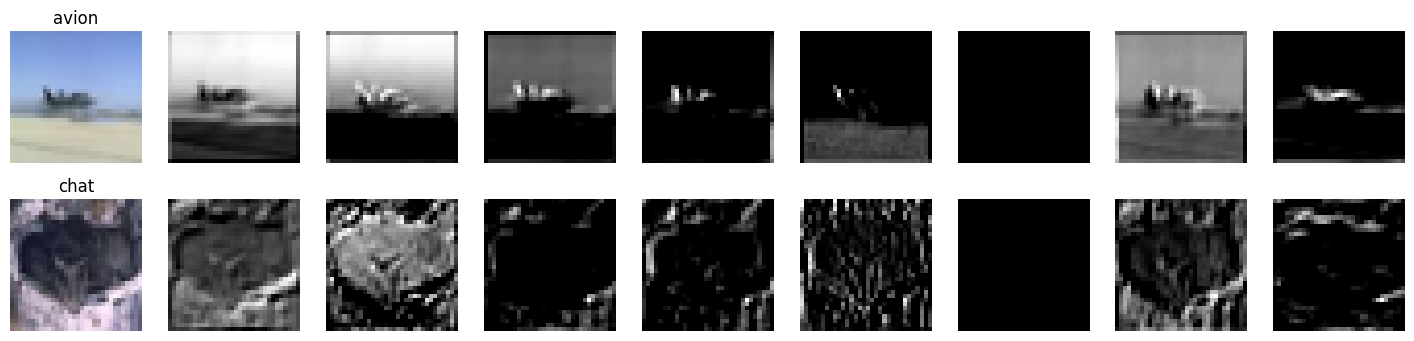

In [ ]:
import matplotlib.pyplot as plt

model.eval()
fig, axes = plt.subplots(2, 9, figsize=(18, 4))
for ligne, classe in enumerate(("avion", "chat")):
    image, _ = val_ds[val_ds.targets.index(val_ds.class_to_idx[classe])]
    with torch.no_grad():
        maps = model.bloc1[1](model.bloc1[0](image.unsqueeze(0).to(device))).cpu()
    axes[ligne, 0].imshow(image.permute(1, 2, 0) * 0.5 + 0.5)
    axes[ligne, 0].set_title(classe)
    for k in range(8):
        axes[ligne, k + 1].imshow(maps[0, k], cmap="gray")
    for ax in axes[ligne]:
        ax.axis("off")
plt.show()

**Corrigé.** Chaque feature map est une image de 32 x 32 : les zones claires sont celles où le filtre répond. Sur l'avion, certaines cartes séparent le ciel du sol ; sur le chat, d'autres soulignent des contours et la texture du pelage. La septième carte est entièrement noire pour les deux images : ce canal ne répond jamais après la ReLU, c'est un neurone mort, un phénomène étudié au jour 2.

## Étape 5 : le CNN face au MLP du TP2 (fourni)

On réentraîne ici un MLP identique à la baseline du TP2 (images aplaties en 3072 valeurs), avec la boucle de ce TP : son accuracy peut différer un peu de celle obtenue au TP2. Puis on compare les deux modèles sur la même validation.

In [ ]:
from torch.utils.data import TensorDataset

vers_vecteur = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])


def charger_tenseurs(partie):
    dataset = ImageFolder(f"cifar10/{partie}", transform=vers_vecteur)
    return TensorDataset(torch.stack([image for image, _ in dataset]).flatten(1), torch.tensor(dataset.targets))

In [ ]:
torch.manual_seed(0)
mlp_train = DataLoader(charger_tenseurs("train"), batch_size=64, shuffle=True)
mlp = nn.Sequential(nn.Linear(3072, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)
for epoch in range(20):
    train_one_epoch(mlp, mlp_train, nn.CrossEntropyLoss(), optimizer)

In [ ]:
mlp_val = DataLoader(charger_tenseurs("val"), batch_size=256)
print(f"MLP (pixels aplatis) : accuracy val {evaluate(mlp, mlp_val, loss_fn)[1]:.3f}")
print(f"CNN                  : accuracy val {evaluate(model, val_loader, loss_fn)[1]:.3f}")

MLP (pixels aplatis) : accuracy val 0.374


CNN                  : accuracy val 0.509


Question : d'où vient l'écart ? Qu'est-ce que la convolution exploite que le MLP ne voit pas ?

**Corrigé.** Sur la même validation, le CNN atteint 0.509 contre 0.374 pour le MLP. La convolution exploite le voisinage des pixels et partage ses poids : un motif est reconnu où qu'il soit dans l'image, avec plus de quatre fois moins de paramètres que le MLP.

## Bonus

**B1.** Calculez la matrice de confusion du CNN sur la validation : ligne = vraie classe, colonne = classe prédite. Quelles classes sont le plus souvent confondues ?

In [ ]:
confusion = torch.zeros(10, 10, dtype=torch.int64)
model.eval()
with torch.no_grad():
    for x, y in val_loader:
        for vraie, predite in zip(y, model(x.to(device)).argmax(1).cpu()):
            confusion[vraie, predite] += 1
print(val_ds.classes)
print(confusion)

['automobile', 'avion', 'bateau', 'camion', 'cerf', 'chat', 'cheval', 'chien', 'grenouille', 'oiseau']
tensor([[73,  5,  5, 18,  1,  0,  0,  0,  1,  0],
        [ 9, 66, 10, 12,  3,  0,  2,  1,  0,  6],
        [ 8, 18, 67,  3,  2,  1,  0,  1,  0,  2],
        [17,  4,  5, 50,  0,  0,  5,  0,  2,  1],
        [ 0,  8,  2,  1, 40,  2, 13,  7, 10, 13],
        [ 2,  3,  2,  2,  5,  8,  8, 49, 19, 14],
        [ 0,  3,  0,  5,  5,  5, 58, 14,  1,  4],
        [ 1,  3,  1,  1,  7, 10, 10, 58,  8, 12],
        [ 1,  3,  1,  6, 11,  4,  4,  4, 58,  7],
        [ 2, 11,  2,  2, 16,  0, 10,  5, 10, 31]])


**Corrigé.** La diagonale porte les bonnes réponses : automobile (73), bateau (67) et avion (66) sont les mieux reconnus. Le chat est presque toujours raté : 8 bonnes réponses seulement, et 49 chats classés chiens. Les confusions suivent la ressemblance : chat et chien, automobile et camion (18 automobiles prises pour des camions, 17 camions pour des automobiles).

**B2.** Réentraînez le même CNN sans augmentation. L'écart avec l'entraînement change-t-il ?

In [ ]:
sans_aug = DataLoader(ImageFolder("cifar10/train", transform=eval_tf), batch_size=32, shuffle=True)
torch.manual_seed(0)
model_sans_aug = CNNCifar().to(device)
optimizer = torch.optim.Adam(model_sans_aug.parameters(), lr=1e-3)
for epoch in range(10):
    train_one_epoch(model_sans_aug, sans_aug, loss_fn, optimizer)
print(f"acc trn {evaluate(model_sans_aug, sans_aug, loss_fn)[1]:.3f}  acc val {evaluate(model_sans_aug, val_loader, loss_fn)[1]:.3f}")

acc trn 0.637  acc val 0.518


**Corrigé.** Sans augmentation, l'écart se creuse : 0.637 en entraînement contre 0.518 en validation. L'accuracy de validation reste voisine sur dix époques, mais le modèle mémorise déjà le jeu d'entraînement : l'augmentation freine cette mémorisation.